# SETSUNA demo

SETSUNA infers spikes from calcium imaging on a time grid finer than the imaging frame. This notebook runs it on one
jGCaMP8s neuron whose spikes were recorded electrically at the same time, and compares the inferred spikes with the
recorded ones.

**Data.** `jGCaMP8s_ANM479572_cell08.npz` (0.2 MB, in this folder): raw and neuropil fluorescence, frame times and
loose-seal spike times of one neuron from DANDI:000168 (Zhang, Rózsa et al., *Nature* 2023), CC BY 4.0; see
`DATA_LICENSE.md`. The neuron is part of the public ground truth SETSUNA was trained on, so this notebook shows how to
run the software and what it returns, not held-out accuracy.

**Requirements.** `pip install setsuna matplotlib` (see the user guide for PyTorch with CUDA). The trained models
(about 64 MB) are downloaded the first time SETSUNA runs. The whole notebook runs in well under a minute.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import setsuna

print("setsuna", setsuna.__version__)

setsuna 0.9.0


## 1. Load the recording

The neuron was imaged at 122 Hz. To mimic a typical experiment, keep every fourth frame (30.5 Hz).

In [2]:
d = np.load("jGCaMP8s_ANM479572_cell08.npz")
step = 4
F, Fneu, t = d["F"][::step], d["Fneu"][::step], d["frame_times"][::step]
fps = float(d["fps"]) / step
t = t - t[0]
spikes = d["spike_times"] - d["frame_times"][0]
spikes = spikes[(spikes >= 0) & (spikes < t[-1] + 1 / fps)]
print(f"{len(t)} frames, {len(t) / fps:.0f} s at {fps:.1f} Hz, {len(spikes)} recorded spikes")

5185 frames, 170 s at 30.5 Hz, 127 recorded spikes


## 2. dF/F

SETSUNA reads fractional dF/F (0.5 = a 50% increase). From raw and neuropil fluorescence, use its own function
(neuropil coefficient 0.7, a 60-s maximin baseline).

In [3]:
dff = setsuna.dff_from_fluorescence(F[None], Fneu[None], fps=fps)
print(dff.shape)

(1, 5185)


## 3. Infer spikes

`tolerance_ms` is the spike-timing precision the analysis needs (here 25 ms); SETSUNA picks its spike-time decoder from
it. `smooth_ms=25` also returns the smoothed sub-frame rate, the recommended output for firing-rate analyses, and
`bins_per_frame=16` the raw sub-frame streams pooled to 16 bins per frame. This demo runs on the CPU; use
`device="auto"` to run on a GPU.

In [4]:
t0 = time.time()
out = setsuna.infer(dff, fps=fps, indicator="jGCaMP8s", cell_type="pyramidal",
                    tolerance_ms=25, smooth_ms=25, bins_per_frame=16, device="cpu")
print(f"run time {time.time() - t0:.1f} s (including loading the models)")
print("outputs:", {k: (v.shape if hasattr(v, "shape") else type(v).__name__) for k, v in out.items()})

run time 2.1 s (including loading the models)
outputs: {'rate': (1, 5185), 'nu': (1,), 'fps': 'float', 'indicator': 'str', 'cell_type': 'str', 'band': 'str', 'tolerance_ms': 'int', 'spike_times': 'list', 'rate_smooth': (1, 41480), 't_smooth': (41480,), 'smooth_ms': 'float', 'smooth_bins_per_frame': 'int', 'count': (1, 82960), 'prob': (1, 82960), 'bins_per_frame': 'int', 'spike_counts': (1, 82960)}


`rate` is the expected number of spikes in each frame: it can be fractional (0.3 = 0.3 spikes expected) or above 1
(a burst within one frame), its sum over frames is the expected total, and `rate * fps` is in spikes per second.
`count` is the same estimate in 16 bins per frame (each 1/16 of a frame, about 2 ms here); the 16 bins of a frame add
up to that frame's `rate`. `rate_smooth` is the sub-frame rate smoothed with a 25-ms Gaussian, in spikes per second,
with its bin times in `t_smooth` (seconds from the first frame). `spike_times` are the decoded spike times (s) at the
chosen tolerance, `spike_counts` the same spikes counted per bin, `prob` the within-frame stream and `nu` the noise
level.

**Which output to use.** For firing-rate analyses (tuning, correlations, trial-averaged responses) use `rate_smooth`;
for timing analyses (when spikes occur, response onsets and latencies, synchrony) use `spike_times`; for analyses
binned at the imaging frame, `rate`.

## 4. Compare with the recorded spikes

`tolerance_ms` picks the spike-time decoder. Below one frame (and below 35 ms), as here at 25 ms, the **timing
decoder** places the expected number of spikes at the strongest peaks within the frame: precise, but weak single spikes
can lose out to stronger events nearby. At one frame or more, the **detection decoder** finds events from the count
output and places one spike per event within its frame. For comparison, decode the same recording also at 50 ms.

In [5]:
rate, inferred = out["rate"][0], out["spike_times"][0]                        # timing decoder (25 ms)
det = setsuna.infer(dff, fps=fps, indicator="jGCaMP8s", tolerance_ms=50, device="cpu")["spike_times"][0]   # detection

def matched(true_t, inferred_t, tol_s):
    """Recorded spikes with an inferred spike within +-tol_s, one-to-one, in time order."""
    used = np.zeros(len(inferred_t), bool)
    n = 0
    for s in true_t:
        j = np.flatnonzero(~used & (np.abs(inferred_t - s) <= tol_s))
        if j.size:
            used[j[np.argmin(np.abs(inferred_t[j] - s))]] = True
            n += 1
    return n

print(f"recorded spikes : {len(spikes)}")
print(f"expected spikes : {rate.sum():.1f} (sum of the rate)")
for name, st in (("timing decoder (25 ms)", inferred), ("detection decoder (50 ms)", det)):
    print(f"{name}: {len(st)} spikes;", ", ".join(
        f"within +-{tol * 1000:.0f} ms {matched(spikes, st, tol)} of {len(spikes)}" for tol in (0.025, 0.1)))

recorded spikes : 127
expected spikes : 121.4 (sum of the rate)
timing decoder (25 ms): 121 spikes; within +-25 ms 95 of 127, within +-100 ms 105 of 127
detection decoder (50 ms): 113 spikes; within +-25 ms 102 of 127, within +-100 ms 110 of 127


## 5. Plot

Top, 30 s of dF/F with the recorded spike times (black) and those of the timing decoder (blue, 25 ms) and the
detection decoder (orange, 50 ms). Middle, the firing rate: the smoothed
sub-frame rate (`rate_smooth`, blue) against the recorded spikes smoothed with the same 25-ms Gaussian (black), with the
per-frame `rate` as a staircase (gray). Bottom, a 2-s zoom: the raw sub-frame stream (`count`, 16 bins per frame, gray)
and the smoothed sub-frame rate (`rate_smooth`, blue), both in spikes per second, with the frame boundaries and the
recorded spikes (black).

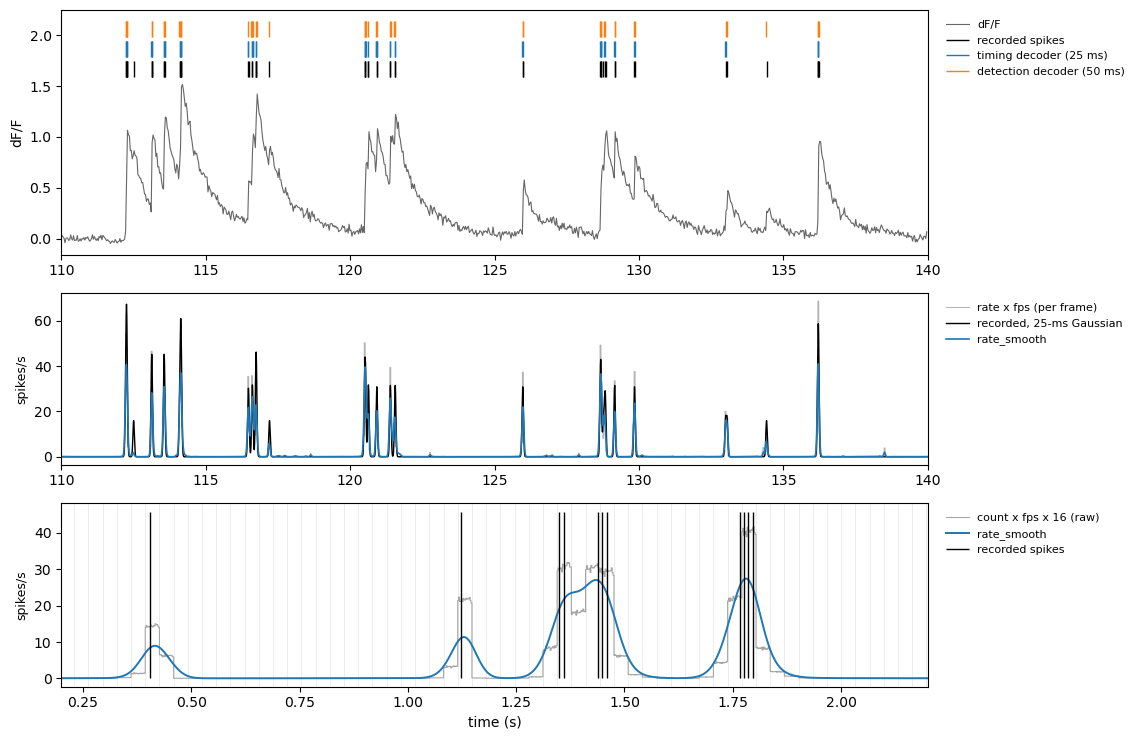

correlation of rate_smooth with the recorded spikes (both 25-ms Gaussian): 0.947


In [6]:
from scipy.ndimage import gaussian_filter1d

win = (110, 140)          # 30 s with many spikes
k = out["bins_per_frame"]
tf = np.arange(rate.size * k) / (fps * k)
sel = (t >= win[0]) & (t < win[1])
ts, rsm = out["t_smooth"], out["rate_smooth"][0]                # spikes/s on the smoothing grid
dts = ts[1] - ts[0]
true_sm = gaussian_filter1d(np.histogram(spikes, np.append(ts - dts / 2, ts[-1] + dts / 2))[0] / dts, 0.025 / dts)
ss = (ts >= win[0]) & (ts < win[1])
fig, ax = plt.subplots(3, 1, figsize=(11.5, 7.5), gridspec_kw={"height_ratios": [2, 1.4, 1.5]})
leg = dict(loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=8)
ax[0].plot(t[sel], dff[0, sel], color="0.4", lw=0.8, label="dF/F")
ymax = dff[0, sel].max()
rs = spikes[(spikes >= win[0]) & (spikes < win[1])]
ins = inferred[(inferred >= win[0]) & (inferred < win[1])]
dts_ = det[(det >= win[0]) & (det < win[1])]
ax[0].vlines(rs, ymax * 1.05, ymax * 1.15, color="k", lw=1, label="recorded spikes")
ax[0].vlines(ins, ymax * 1.18, ymax * 1.28, color="tab:blue", lw=1, label="timing decoder (25 ms)")
ax[0].vlines(dts_, ymax * 1.31, ymax * 1.41, color="tab:orange", lw=1, label="detection decoder (50 ms)")
ax[0].set_ylabel("dF/F"); ax[0].legend(**leg); ax[0].set_xlim(win)
ax[1].step(t[sel], rate[sel] * fps, where="post", color="0.7", lw=0.7, label="rate x fps (per frame)")
ax[1].plot(ts[ss], true_sm[ss], color="k", lw=1.0, label="recorded, 25-ms Gaussian")
ax[1].plot(ts[ss], rsm[ss], color="tab:blue", lw=1.2, label="rate_smooth")
ax[1].set_ylabel("spikes/s", fontsize=9); ax[1].set_xlim(win); ax[1].legend(**leg)
z = (0.2, 2.2)            # a single spike and two bursts
sz = (tf >= z[0]) & (tf < z[1]); sz2 = (ts >= z[0]) & (ts < z[1])
ax[2].step(tf[sz], out["count"][0, sz] * fps * k, where="post", color="0.65", lw=0.8,
           label="count x fps x 16 (raw)")
ax[2].plot(ts[sz2], rsm[sz2], color="tab:blue", lw=1.4, label="rate_smooth")
for fb in t[(t >= z[0]) & (t < z[1])]:
    ax[2].axvline(fb, color="0.9", lw=0.5, zorder=0)
zr = spikes[(spikes >= z[0]) & (spikes < z[1])]
top = max(out["count"][0, sz].max() * fps * k, rsm[sz2].max()) * 1.1 if sz.any() else 1
ax[2].vlines(zr, 0, top, color="k", lw=1, label="recorded spikes")
ax[2].set_xlim(z); ax[2].set_ylabel("spikes/s", fontsize=9); ax[2].set_xlabel("time (s)"); ax[2].legend(**leg)
plt.tight_layout(); plt.show()
print(f"correlation of rate_smooth with the recorded spikes (both 25-ms Gaussian): {np.corrcoef(rsm, true_sm)[0, 1]:.3f}")

## 6. Smoothed rate for a subset

`setsuna.smooth_rate` smooths a sub-frame count stream you already have (here `count`, 16 bins per frame) for chosen
neurons and a time window, with the same values as for the whole recording: useful when `rate_smooth` for every neuron
of a long recording would be too large to keep.

In [7]:
sub = setsuna.smooth_rate(out["count"], fps=fps, bins_per_frame=out["bins_per_frame"], smooth_ms=25,
                          neurons=[0], start_s=120, end_s=130)
same = np.allclose(sub["rate_smooth"][0], out["rate_smooth"][0][(out["t_smooth"] >= sub["t_smooth"][0]) &
                                                               (out["t_smooth"] <= sub["t_smooth"][-1])], rtol=1e-3, atol=1e-3)
print(sub["rate_smooth"].shape, f"{sub['t_smooth'][0]:.3f}-{sub['t_smooth'][-1]:.3f} s", "| equals the whole-recording values:", same)

(1, 2448) 119.998-130.030 s | equals the whole-recording values: True


## 7. Rates only

Without spike times (`tolerance_ms=None`), SETSUNA returns only `rate` and `nu` (and `rate_smooth` with `smooth_ms`),
which is faster for large recordings.

In [8]:
r = setsuna.infer(dff, fps=fps, indicator="jGCaMP8s", tolerance_ms=None, device="cpu")
print(sorted(r.keys()))

['band', 'cell_type', 'fps', 'indicator', 'nu', 'rate', 'tolerance_ms']
